# Comprehensive Work: Aerodynamic Airfoil Reconstruction via Interpolation Methods
## Problem Statement & Mathematical Formulation

The objective is to reconstruct the geometry of a randomly generated cambered **NACA 4-digit airfoil** from discrete support nodes using two numerical schemes:
1. **Lagrange Polynomial Interpolation**
2. **Natural Cubic Spline Interpolation**
   
The interpolated geometries are compared against the exact analytical curves to quantify interpolation error.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
#dedfining lagrange interpolation function
def Lagrange(x,y,xx):
    t_sum = 0
    n = len(x)
    for i in range(n):
        product = y[i]
        for j in range(n):
            if i != j :
                product = product*(xx-x[j])/(x[i]-x[j])
        t_sum = t_sum+product 
    return t_sum


In [7]:
Lagrange([1,2,3],[1,4,9],0.5)

0.25

In [8]:
#air foil generation

m = np.random.uniform(0.02,0.05)
p= np.random.uniform(0.3,0.5)
t = np.random.uniform(0.1,0.15)

x = np.linspace(0,1,1000)
y_t = 5*t*(0.2969*np.sqrt(x)-0.1260*x-0.3516*x**2+0.2843*x**3-0.1036*x**4)

y_c = np.where(x<=p,
         m*(2*p*x-x**2)/p**2,
         m*((1-2*p)+2*p*x-x**2)/(1-p)**2)

dy_dx = np.where(x<=p,
          2*m*(p-x)/p**2,
          2*m*(p-x)/(1-p)**2)

theta = np.arctan (dy_dx)

x_u = x-y_t*np.sin(theta)
x_l = x+y_t*np.sin(theta)

y_u = y_c + y_t*np.cos(theta)
y_l = y_c - y_t*np.cos (theta)

    



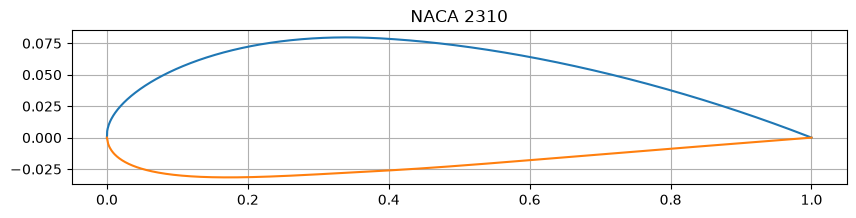

In [9]:
#plotting the air foil 
plt.figure(figsize=(10,2))
plt.plot(x_u,y_u)
plt.plot(x_l,y_l)
plt.grid(True)
plt.title(f"NACA {int(100*m)}{int(10*p)}{int(100*t)}")
plt.show()

In [10]:
#using lagrange interpolatioin to generate airfoil

x_u_sample = x_u[::90]
x_l_sample = x_l[::90]
y_u_sample = y_u[::90]
y_l_sample = y_l[::90]

U_lagrange = Lagrange(x_u_sample,y_u_sample,x_u)
L_lagrange = Lagrange(x_l_sample,y_l_sample,x_l)

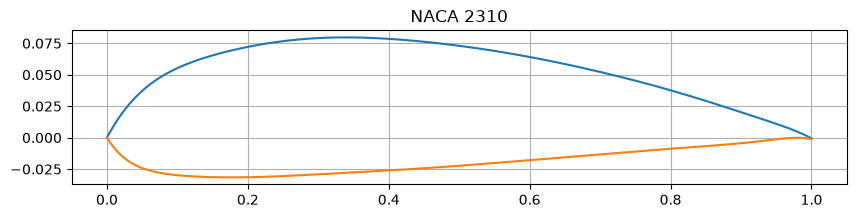

In [11]:
#plotting reconstructed airfoil using lagrange interpolation

plt.figure(figsize=(10,2))
plt.plot(x_u,U_lagrange)
plt.plot(x_l,L_lagrange)
plt.grid(True)
plt.title(f"NACA {int(100*m)}{int(10*p)}{int(100*t)}")
plt.show()

In [12]:
#finding the error between original airfoil and reconstructed airfoil

error_u = np.max(np.abs(y_u-U_lagrange))
error_l = np.max(np.abs(y_l-L_lagrange))

rms_u = np.sqrt(np.mean((y_u-U_lagrange)**2))
rms_l = np.sqrt(np.mean((y_l-L_lagrange)**2))

print ("maximum mean absolute error at uppper surface =",error_u)
print ("maximum mean absolute error at lower surface =",error_l)
print ("rms error at uppper surface =",rms_u)
print ("rms error at lower surface =",rms_l)

maximum mean absolute error at uppper surface = 0.008642934831183557
maximum mean absolute error at lower surface = 0.004821885672267194
rms error at uppper surface = 0.0014936308721366991
rms error at lower surface = 0.000694145092201246


In [14]:
#definig cubic spline interpolation function 

def cubic_spline(x,y,xx):

    sort_idx = np.argsort(x)
    x = x[sort_idx]
    y = y[sort_idx]
    n = len(x)
    h = np.diff(x)
    c = np.zeros(n)
    
    lower_dia = np.zeros(n)
    upper_dia = np.zeros(n)
    main_dia = np.zeros(n)
    rhs = np.zeros(n)

    for i in range(1,n-1):

        rhs[i] = (3/h[i])*(y[i+1]-y[i]) -(3/h[i-1])*(y[i]-y[i-1]) 

        lower_dia[i] = h[i-1]

        main_dia[i]= 2*(h[i-1]+h[i])

        upper_dia[i]= h[i]

    for i in range(2,n-2):
            
        factor = lower_dia[i]/main_dia[i-1]
        main_dia[i] = main_dia[i]-factor*upper_dia[i-1]
        rhs[i] = rhs[i]-factor*rhs[i-1]
        
    if n > 2:
        c[n - 2] = rhs[n - 2] / main_dia[n - 2]

    for i in range(n-3,0,-1):
        c[i] = (rhs[i]-upper_dia[i]*c[i+1])/main_dia[i]

    i = np.searchsorted(x, xx) - 1
    i = np.clip(i, 0, n - 2)
    
    del_x = xx - x[i]

    hi = h[i]
    yi = y[i]
    yip1 = y[i + 1]
    ci = c[i]
    cip1 = c[i + 1]

    a = yi
    b = (yip1 - yi) / hi - (hi / 3) * (2 * ci + cip1)
    d = (cip1 - ci) / (3 * hi)

    result = a + b * del_x + ci * del_x**2 + d * del_x**3

    return result


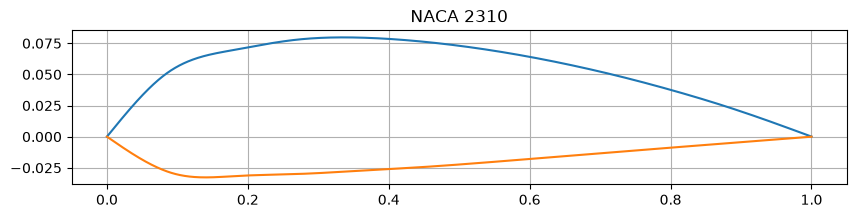

In [15]:
U_spline = cubic_spline(x_u_sample,y_u_sample,x_u)
L_spline = cubic_spline(x_l_sample,y_l_sample,x_l)

plt.figure(figsize=(10,2))
plt.plot(x_u,U_spline)
plt.plot(x_l,L_spline)
plt.grid(True)
plt.title(f"NACA {int(100*m)}{int(10*p)}{int(100*t)}")
plt.show()

In [16]:
error_u_spline = np.max(np.abs(y_u-U_spline))
error_l_spline = np.max(np.abs(y_l-L_spline))

rms_u_spline = np.sqrt(np.mean((y_u-U_spline)**2))
rms_l_spline = np.sqrt(np.mean((y_l-L_spline)**2))

print ("maximum mean absolute error at uppper surface =",error_u_spline)
print ("maximum mean absolute error at lower surface =",error_l_spline)
print ("rms error at uppper surface =",rms_u_spline)
print ("rms error at lower surface =",rms_l_spline)

maximum mean absolute error at uppper surface = 0.011850135583323216
maximum mean absolute error at lower surface = 0.00972474288938607
rms error at uppper surface = 0.002457198750337118
rms error at lower surface = 0.001984020766468892


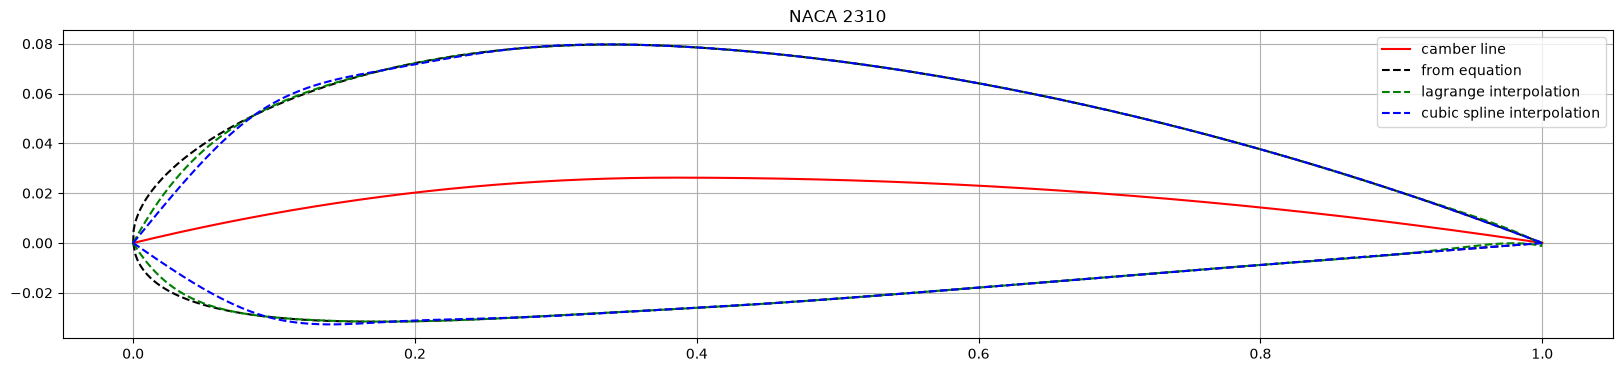

In [17]:
#plotting all three air foils together 

plt.figure(figsize= (20,4))
plt.plot(x,y_c, "r" ,label= "camber line" )
plt.plot(x_u,y_u,"k--",label = "from equation")
plt.plot(x_l,y_l,"k--")
plt.plot(x_u,U_lagrange,"g--",label = "lagrange interpolation")
plt.plot(x_l,L_lagrange,"g--")
plt.plot(x_u,U_spline,"b--",label = "cubic spline interpolation")
plt.plot(x_l,L_spline,"b--")
plt.grid(True)
plt.legend()
plt.title(f"NACA {int(100*m)}{int(10*p)}{int(100*t)}")
plt.show()


## Observations

When uniform node spacing is used with high-degree Lagrange polynomials ($n > 10$) that is when more number of the data points are used , the interpolation error diverges exponentially near the boundaries.

Even if we use lower-degree Lagrange polynomials there is very high interpolation error near the boundaries.

But as the number of data points increases the cubic spline interpolation gives more accurate results with less interpolation error.